# Colegio Universitario de Cartago CUC
### III Cuatrimestre
### Profesor: Ronald Córdoba Vega
### Estudiantes:
- Tiffany Daniela Méndez Quirós
- Mariel Rodriguez Arguello
- Mónica Mendoza Morales
- Isaac Ulloa
- Wedell Orozco González

### Introducción
En la actualidad, las plataformas de streaming musical recopilan una gran cantidad de datos sobre las preferencias y los hábitos de reproducción de sus usuarios. Comprender este comportamiento es fundamental para mejorar la experiencia de escucha y ofrecer recomendaciones más acertadas.

### Propósito general
El objetivo de este proyecto es analizar los hábitos de streaming a través de técnicas de minería de datos, aplicando el ciclo metodológico CRISP-DM mediante programación orientada a objetos. Para lograrlo, utilizaremos los algoritmos de asociación **Apriori**, **FP-Growth** y **ECLAT** sobre un conjunto de datos representativo, con el fin de descubrir patrones ocultos, reglas de asociación relevantes y relaciones clave entre las características de los usuarios y las funciones de la plataforma.



### Descripción de las columnas del Dataset

* **`listener_id`**: Identificador único para cada usuario o escucha registrado en la base de datos.
* **`age`**: Edad del usuario (en años).
* **`country`**: País de origen o residencia del usuario.
* **`platform`**: Plataforma de streaming musical que utiliza principalmente (por ejemplo, Spotify, Apple Music, Amazon Music, etc.).
* **`subscription`**: Tipo de suscripción o plan contratado (por ejemplo, Free, Premium, Student).
* **`top_genre`**: Género musical favorito o más escuchado por el usuario (como Pop, R&B, Clásica, etc.).
* **`top_artist`**: Artista más reproducido por el usuario.
* **`daily_listening_minutes`**: Cantidad total de minutos que el usuario pasa escuchando contenido al día.
* **`songs_per_day`**: Número promedio de canciones reproducidas diariamente.
* **`playlists_count`**: Cantidad de listas de reproducción creadas o guardadas por el usuario.
* **`skip_rate_pct`**: Porcentaje de canciones que el usuario omite (salta) en su día a día.
* **`discover_weekly_user`**: Indicador lógico (`True`/`False`) de si el usuario utiliza o aprovecha habitualmente la lista de recomendación semanal (*Discover Weekly*).
* **`top_mood`**: Estado de ánimo principal asociado a las sesiones de escucha del usuario (por ejemplo, Relax, Workout, Sleep, Happy).
* **`uses_offline_mode`**: Indicador lógico (`True`/`False`) de si el usuario utiliza el modo sin conexión (offline).
* **`podcasts_too`**: Indicador lógico (`True`/`False`) de si el usuario también consume podcasts en la plataforma.


## 1. Librerías

In [1]:
from pathlib import Path
import pandas as pd
import plotly.io as pio
import sys

# Raíz del proyecto (si el notebook corre desde HTML/, se sube un nivel)
RAIZ = Path.cwd()
if not (RAIZ / "DATA").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))

#from TSNE.TSNE import AnalisisTSNE
#from CLASES_POO.EDA.EDA import EDAMusicStreaming
from CLASES_POO.EDA import *
from CLASES_POO.VIZUALIZADOR import VisualizacionMusicStreaming
from CLASES_POO.POO import (
    about_data,
    Reglas_Asociacion,
    Reduccion_Dimensionalidad,
    ClusteringReduccion,
    GraficosClustering,
)
from MODELOS.TSNE.TSNE import *
from MODELOS.UMAP.MODELO_UMAP import MODELO_UMAP

C:\Users\isaac\Desktop\Habitos-Musicales\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Ingesta de datos

In [2]:
raw_songs = about_data(str(RAIZ / "DATA" / "RAW" / "music_streaming_habits_2026.csv"))

Datos cargados con éxito desde la ruta


In [3]:
raw_songs.datos

,listener_id,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,1,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,39.3,False,Sleep,False,True
1,2,21,Germany,Spotify,Free,Classical,Drake,249,68,10,18.3,True,Workout,True,True
2,3,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,22.7,True,Sad,False,True
3,4,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,29.4,True,Sad,True,False
4,5,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,37.7,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3996,26,France,Spotify,Family,Pop,SZA,197,55,6,15.3,False,Workout,True,False
3996,3997,35,Germany,YouTube Music,Free,Rock,Ariana Grande,320,77,13,9.2,True,Sad,False,True
3997,3998,43,India,Apple Music,Free,Hip-Hop,Dua Lipa,99,38,5,14.0,False,Happy,True,True
3998,3999,26,India,Apple Music,Student,Indie,SZA,76,31,7,36.1,False,Happy,False,False


## 3. Exploración, transformación de datos y EDA


In [4]:
eda = EDA(str(RAIZ / "DATA" / "RAW" / "music_streaming_habits_2026.csv"))

eda.cargar_datos()
eda._numericas()
eda._categoricas()
eda.resumen_calidad()
#eda.eliminar_columnas()
#eda.renombrar_columnas()
#eda.revisar_datos()
#eda.convertir_tipos()
#eda.describir_datos()
#eda.guardar_dataset()

   listener_id  age    country      platform subscription  top_genre  \
0            1   24  Australia   Apple Music         Free        R&B   
1            2   21    Germany       Spotify         Free  Classical   
2            3   32      Japan  Amazon Music         Free    Hip-Hop   
3            4   39      Japan   Apple Music         Free        Pop   
4            5   23      India       Spotify       Family    Country   

       top_artist  daily_listening_minutes  songs_per_day  playlists_count  \
0  Kendrick Lamar                      191             54                9   
1           Drake                      249             68               10   
2  Olivia Rodrigo                       49             11               11   
3       Burna Boy                       96             22                8   
4  Olivia Rodrigo                      100             24               13   

   skip_rate_pct  discover_weekly_user top_mood  uses_offline_mode  \
0           39.3            

### 3.1 Gráficos

In [5]:
eda.graficar_distribucion_numericas()
eda.graficar_comparacion_numericas()
eda.graficar_frecuencia_categoricas()
#eda.graficar_minutos_por_plataforma()
#eda.graficar_canciones_por_animo()
#eda.graficar_minutos_vs_canciones()
eda.graficar_matriz_correlacion()

Interpretación: Para listener_id, el promedio es 2000.50 y la mediana es 2000.50. Los valores se encuentran entre 1 y 4000. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para age, el promedio es 27.85 y la mediana es 28.00. Los valores se encuentran entre 13 y 57. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para daily_listening_minutes, el promedio es 138.70 y la mediana es 122.00. Los valores se encuentran entre 5 y 697. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para songs_per_day, el promedio es 39.14 y la mediana es 35.00. Los valores se encuentran entre 1 y 198. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para playlists_count, el promedio es 8.99 y la mediana es 9.00. Los valores se encuentran entre 1 y 22. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para skip_rate_pct, el promedio es 28.16 y la mediana es 28.10. Los valores se encuentran entre 0.0 y 70.9. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


... (7 outputs left out)

Interpretación: La categoría más frecuente en top_mood es 'Sad', con 538 registros (13.5% del total).


Interpretación: La categoría más frecuente en uses_offline_mode es 'False', con 2290 registros (57.2% del total).


Interpretación: La categoría más frecuente en podcasts_too es 'False', con 2128 registros (53.2% del total).


Interpretación: La matriz permite identificar qué variables presentan relaciones lineales más fuertes. La diagonal vale 1 porque cada variable tiene correlación perfecta consigo misma. Las correlaciones no representan necesariamente relaciones de causa y efecto.


In [6]:
# Gráficos específicos del dataset limpio (columnas en español)
viz = VisualizacionMusicStreaming(str(RAIZ / "DATA" / "PROCESSED" / "music_streaming_habits_limpio.csv"))

viz.graficar_minutos_por_plataforma()
viz.graficar_canciones_por_animo()
viz.graficar_minutos_vs_canciones()

Interpretación: La plataforma con el promedio más alto de minutos diarios es SoundCloud, con 145.9 minutos. La comparación describe los hábitos registrados en cada plataforma, pero no demuestra que la plataforma sea la causa de escuchar más música.


Interpretación: El estado de ánimo con el promedio más alto de canciones escuchadas por día es Sleep, con 40.3 canciones. El gráfico permite observar si existen diferencias entre los grupos.


Interpretación: La correlación entre los minutos de escucha y las canciones por día es 0.98, lo que indica una relación positiva marcada. Esto permite observar cómo se relacionan ambas variables, pero no significa que una cause la otra.


In [7]:
# Utilización de la función creada en el archivo "clean.py" clase limpiador de datos
raw_songs.reporte_calidad()

=== Reporte de Diagnóstico y Calidad ===
Total de registros: 4000
Registros duplicados: 0

Detalle de campos y valores faltantes:
No se detectaron valores nulos.


,Tipo de Dato,Valores Nulos,% Nulos
listener_id,int64,0,0.0
age,int64,0,0.0
country,str,0,0.0
platform,str,0,0.0
subscription,str,0,0.0
top_genre,str,0,0.0
top_artist,str,0,0.0
daily_listening_minutes,int64,0,0.0
songs_per_day,int64,0,0.0
playlists_count,int64,0,0.0


In [8]:
# Valores min, max, media ect... de las columnas
raw_songs.datos.describe()

,listener_id,age,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,2000.500000,27.849000,138.702750,39.137500,8.994500,28.163375
std,1154.844867,8.595881,86.296023,25.046296,3.027914,11.815850
min,1.000000,13.000000,5.000000,1.000000,1.000000,0.000000
25%,1000.750000,22.000000,74.000000,21.000000,7.000000,20.000000
50%,2000.500000,28.000000,122.000000,35.000000,9.000000,28.100000
75%,3000.250000,34.000000,185.000000,52.250000,11.000000,36.300000
max,4000.000000,57.000000,697.000000,198.000000,22.000000,70.900000


In [9]:
# Utilización de la función creada en el archivo "POO.py" clase about_data
# Muestra el total de categorías y la distribución para todas las columnas de texto.
raw_songs.resumen_categoricas()

=== RESUMEN DE VARIABLES CATEGÓRICAS (6 columnas) ===

Columna: 'country' | Total valores únicos: 10
------------------------------------------------------------
country
Japan        439
Canada       429
USA          418
Brazil       409
Nigeria      401
Australia    397
India        390
France       377
Germany      371
UK           369
Name: count, dtype: int64

Columna: 'platform' | Total valores únicos: 6
------------------------------------------------------------
platform
Spotify          1591
Apple Music       906
YouTube Music     689
Amazon Music      315
SoundCloud        278
Tidal             221
Name: count, dtype: int64

Columna: 'subscription' | Total valores únicos: 4
------------------------------------------------------------
subscription
Free       1820
Premium    1193
Family      586
Student     401
Name: count, dtype: int64

Columna: 'top_genre' | Total valores únicos: 12
------------------------------------------------------------
top_genre
Pop          721
Hip-Hop

In [10]:
# Selección de columnas necesarias
use_songs = raw_songs.datos[["age", "platform", "subscription", "top_genre", "daily_listening_minutes", "discover_weekly_user", "top_mood", "uses_offline_mode", "podcasts_too"]].copy()
use_songs = about_data(use_songs)
use_songs.datos

Datos cargados con éxito a partir de la tabla


,age,platform,subscription,top_genre,daily_listening_minutes,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,24,Apple Music,Free,R&B,191,False,Sleep,False,True
1,21,Spotify,Free,Classical,249,True,Workout,True,True
2,32,Amazon Music,Free,Hip-Hop,49,True,Sad,False,True
3,39,Apple Music,Free,Pop,96,True,Sad,True,False
4,23,Spotify,Family,Country,100,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...
3995,26,Spotify,Family,Pop,197,False,Workout,True,False
3996,35,YouTube Music,Free,Rock,320,True,Sad,False,True
3997,43,Apple Music,Free,Hip-Hop,99,False,Happy,True,True
3998,26,Apple Music,Student,Indie,76,False,Happy,False,False


### 3.2 Transformación de variables age y daily_listening_minutes

In [11]:
# 1. Categorizar 'age' con etapas de vida realistas
use_songs.datos["age_group"] = pd.cut(
    use_songs.datos["age"],
    bins=[-1, 18, 26, 40, 120],
    labels=["Menor", "Joven_Adulto", "Adulto", "Adulto_Maduro"]
)
use_songs.datos.drop(columns=["age"], inplace=True)

# 2. Categorizar 'daily_listening_minutes' y eliminar la columna numérica original
use_songs.datos["listening_level"] = pd.cut(
    use_songs.datos["daily_listening_minutes"],
    bins=[-1, 60, 120, 1440],
    labels=["Escucha_Baja", "Escucha_Media", "Escucha_Alta"]
)
use_songs.datos.drop(columns=["daily_listening_minutes"], inplace=True)

# 3. Mostrar las primeras filas (use_songs sigue siendo tu objeto LimpiadorDatos)
use_songs.datos.head()

,platform,subscription,top_genre,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too,age_group,listening_level
0,Apple Music,Free,R&B,False,Sleep,False,True,Joven_Adulto,Escucha_Alta
1,Spotify,Free,Classical,True,Workout,True,True,Joven_Adulto,Escucha_Alta
2,Amazon Music,Free,Hip-Hop,True,Sad,False,True,Adulto,Escucha_Baja
3,Apple Music,Free,Pop,True,Sad,True,False,Adulto,Escucha_Media
4,Spotify,Family,Country,True,Workout,True,True,Joven_Adulto,Escucha_Media


* **Transformación numérica a categórica:** Se convirtieron dos variables continuas en categorías para facilitar el análisis de asociación:
  * **Edad (`age`):** Se agrupó en etapas de vida (`Menor`, `Joven_Adulto`, `Adulto`, `Adulto_Maduro`).
  * **Minutos de escucha (`daily_listening_minutes`):** Se categorizó en niveles de uso (`Escucha_Baja`, `Escucha_Media`, `Escucha_Alta`).
* **Limpieza:** Se eliminaron las columnas numéricas originales del DataFrame una vez reemplazadas por sus respectivas categorías.

In [12]:
use_songs.datos

,platform,subscription,top_genre,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too,age_group,listening_level
0,Apple Music,Free,R&B,False,Sleep,False,True,Joven_Adulto,Escucha_Alta
1,Spotify,Free,Classical,True,Workout,True,True,Joven_Adulto,Escucha_Alta
2,Amazon Music,Free,Hip-Hop,True,Sad,False,True,Adulto,Escucha_Baja
3,Apple Music,Free,Pop,True,Sad,True,False,Adulto,Escucha_Media
4,Spotify,Family,Country,True,Workout,True,True,Joven_Adulto,Escucha_Media
...,...,...,...,...,...,...,...,...,...
3995,Spotify,Family,Pop,False,Workout,True,False,Joven_Adulto,Escucha_Alta
3996,YouTube Music,Free,Rock,True,Sad,False,True,Adulto,Escucha_Alta
3997,Apple Music,Free,Hip-Hop,False,Happy,True,True,Adulto_Maduro,Escucha_Media
3998,Apple Music,Student,Indie,False,Happy,False,False,Joven_Adulto,Escucha_Media


In [13]:
# Utilización de la función creada en el archivo "POO.py" clase about_data (se le aplico a los datos iniciales de momento no utilizada)
#use_songs.estandarizar()

In [14]:
# Utilización de la función creada en el archivo "POO.py" clase about_data
# Muestra el total de categorías y la distribución para todas las columnas de texto sobre los datos a utilizar.
use_songs.resumen_categoricas()

=== RESUMEN DE VARIABLES CATEGÓRICAS (6 columnas) ===

Columna: 'platform' | Total valores únicos: 6
------------------------------------------------------------
platform
Spotify          1591
Apple Music       906
YouTube Music     689
Amazon Music      315
SoundCloud        278
Tidal             221
Name: count, dtype: int64

Columna: 'subscription' | Total valores únicos: 4
------------------------------------------------------------
subscription
Free       1820
Premium    1193
Family      586
Student     401
Name: count, dtype: int64

Columna: 'top_genre' | Total valores únicos: 12
------------------------------------------------------------
top_genre
Pop          721
Hip-Hop      605
Rock         472
EDM          382
R&B          341
Indie        327
K-Pop        278
Afrobeats    210
Lo-fi        201
Classical    166
Name: count, dtype: int64
... y 2 valores más.

Columna: 'top_mood' | Total valores únicos: 8
------------------------------------------------------------
top_mood
Sa

In [15]:
# Convierte variables categóricas en columnas binarias (True/False)
use_songs = pd.get_dummies(use_songs.datos, prefix_sep=": ", dtype=bool)

In [16]:
use_songs = about_data(use_songs)

Datos cargados con éxito a partir de la tabla


In [17]:
use_songs.datos

,discover_weekly_user,uses_offline_mode,podcasts_too,platform: Amazon Music,platform: Apple Music,platform: SoundCloud,platform: Spotify,platform: Tidal,platform: YouTube Music,subscription: Family,...,top_mood: Sad,top_mood: Sleep,top_mood: Workout,age_group: Menor,age_group: Joven_Adulto,age_group: Adulto,age_group: Adulto_Maduro,listening_level: Escucha_Baja,listening_level: Escucha_Media,listening_level: Escucha_Alta
0,False,False,True,False,True,False,False,False,False,False,...,False,True,False,False,True,False,False,False,False,True
1,True,True,True,False,False,False,True,False,False,False,...,False,False,True,False,True,False,False,False,False,True
2,True,False,True,True,False,False,False,False,False,False,...,True,False,False,False,False,True,False,True,False,False
3,True,True,False,False,True,False,False,False,False,False,...,True,False,False,False,False,True,False,False,True,False
4,True,True,True,False,False,False,True,False,False,True,...,False,False,True,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,False,True,False,False,False,False,True,False,False,True,...,False,False,True,False,True,False,False,False,False,True
3996,True,False,True,False,False,False,False,False,True,False,...,True,False,False,False,False,True,False,False,False,True
3997,False,True,True,False,True,False,False,False,False,False,...,False,False,False,False,False,False,True,False,True,False
3998,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False


## 4. Reglas de asociación Apriori, FP-Growth y Eclat

In [18]:
fp_model = Reglas_Asociacion(use_songs.datos)

### 4.1 Apriori

In [19]:
# 2. Entrenar ('fpgrowth', 'apriori' o 'eclat')
fp_model.fit(metodo="apriori", min_support=0.03, min_confidence=0.5)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({uses_offline_mode}),frozenset({discover_weekly_user}),0.42750,0.57000,0.24775,0.579532,1.016723,1.0,0.004075,1.022670,0.028730,0.330443,0.022168,0.507091
1,frozenset({podcasts_too}),frozenset({discover_weekly_user}),0.46800,0.57000,0.26400,0.564103,0.989654,1.0,-0.002760,0.986471,-0.019273,0.341085,-0.013715,0.513630
2,frozenset({platform: Amazon Music}),frozenset({discover_weekly_user}),0.07875,0.57000,0.04425,0.561905,0.985798,1.0,-0.000637,0.981522,-0.015398,0.073201,-0.018826,0.319768
3,frozenset({platform: Apple Music}),frozenset({discover_weekly_user}),0.22650,0.57000,0.12975,0.572848,1.004996,1.0,0.000645,1.006667,0.006427,0.194601,0.006623,0.400240
4,frozenset({platform: SoundCloud}),frozenset({discover_weekly_user}),0.06950,0.57000,0.04150,0.597122,1.047583,1.0,0.001885,1.067321,0.048814,0.069398,0.063075,0.334965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,"frozenset({subscription: Free, podcasts_too, l...",frozenset({age_group: Adulto}),0.06550,0.47575,0.03350,0.511450,1.075040,1.0,0.002338,1.073074,0.074695,0.065977,0.068098,0.290933
343,"frozenset({podcasts_too, age_group: Adulto, su...",frozenset({listening_level: Escucha_Alta}),0.06550,0.50850,0.03475,0.530534,1.043332,1.0,0.001443,1.046935,0.044443,0.064441,0.044831,0.299436
344,"frozenset({podcasts_too, subscription: Premium...",frozenset({age_group: Adulto}),0.06650,0.47575,0.03475,0.522556,1.098384,1.0,0.003113,1.098035,0.095953,0.068473,0.089283,0.297799
345,"frozenset({age_group: Adulto, subscription: Pr...",frozenset({listening_level: Escucha_Alta}),0.06100,0.50850,0.03275,0.536885,1.055822,1.0,0.001732,1.061292,0.056305,0.061015,0.057752,0.300645


<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación de resultados APRIORI</div></div>

* **Hallazgos principales:** Las reglas generadas muestran una fuerte relación entre el uso de características específicas (como el modo offline, los podcasts o plataformas como Amazon Music y Apple Music) y la adopción de funciones principales de la plataforma como `discover_weekly_user`, lo que nos hace identificar patrones de consumo amplios y consistentes en la base de datos.

In [20]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por="lift", lift_minimo=1.15)
print(tabla_reglas)

                                           antecedents  \
251  frozenset({podcasts_too, discover_weekly_user,...   
334  frozenset({age_group: Joven_Adulto, uses_offli...   
198    frozenset({uses_offline_mode, top_mood: Chill})   
333  frozenset({subscription: Free, age_group: Jove...   
332  frozenset({subscription: Free, uses_offline_mo...   
327  frozenset({podcasts_too, uses_offline_mode, li...   
331  frozenset({uses_offline_mode, platform: Spotif...   
36                         frozenset({top_genre: R&B})   
328  frozenset({uses_offline_mode, listening_level:...   
346  frozenset({subscription: Premium, platform: Sp...   

                                    consequents  support  confidence      lift  
251              frozenset({uses_offline_mode})  0.03075    0.521186  1.219150  
334             frozenset({subscription: Free})  0.03625    0.551331  1.211716  
198                   frozenset({podcasts_too})  0.03050    0.564815  1.206869  
333              frozenset({uses_offl

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación de resultados de reglas con mayor lift en APRIORI</div></div>

* **Hallazgo clave:** Los resultados muestran valores de *lift* superiores a 1.16 y que llegan hasta 1.22 en combinaciones donde intervienen variables como el modo offline, tipos de suscripción (*Free*), grupos de edad (*Adulto* / *Joven_Adulto*) y consumo de podcasts. Lo que nos confirma una fuerte dependencia e interés cruzado entre estas características dentro del comportamiento de los usuarios.

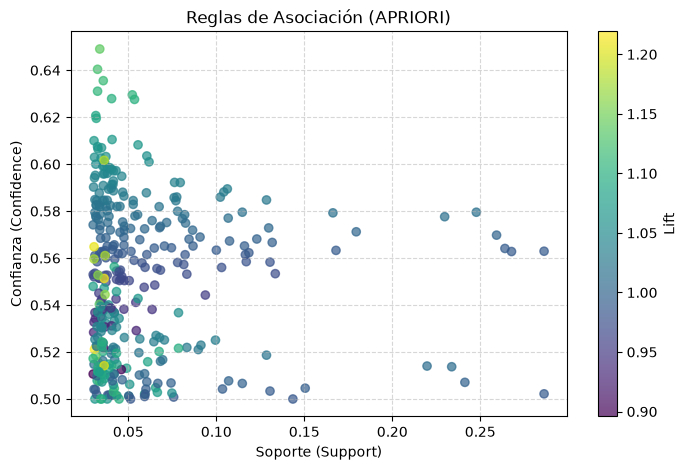

In [21]:
fp_model.graficar_dispersion()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Gráfico de Dispersión (APRIORI)</div></div>

* **Distribución de métricas:** Se observa una alta densidad de reglas concentradas en soportes bajos (cercanos a 0.03 - 0.05), alcanzando niveles de confianza superiores a 0.60.
* **Relación de interés:** Las reglas con mayor *Lift* (tonos amarillos y verde claro, superando valores de 1.15 a 1.20) se localizan principalmente en los rangos de soporte más bajos. Lo que indica que, aunque los patrones más fuertes y específicos no ocurren de forma masiva en toda la base de datos, poseen una alta relevancia estadística y dependencia positiva entre las características de los usuarios.

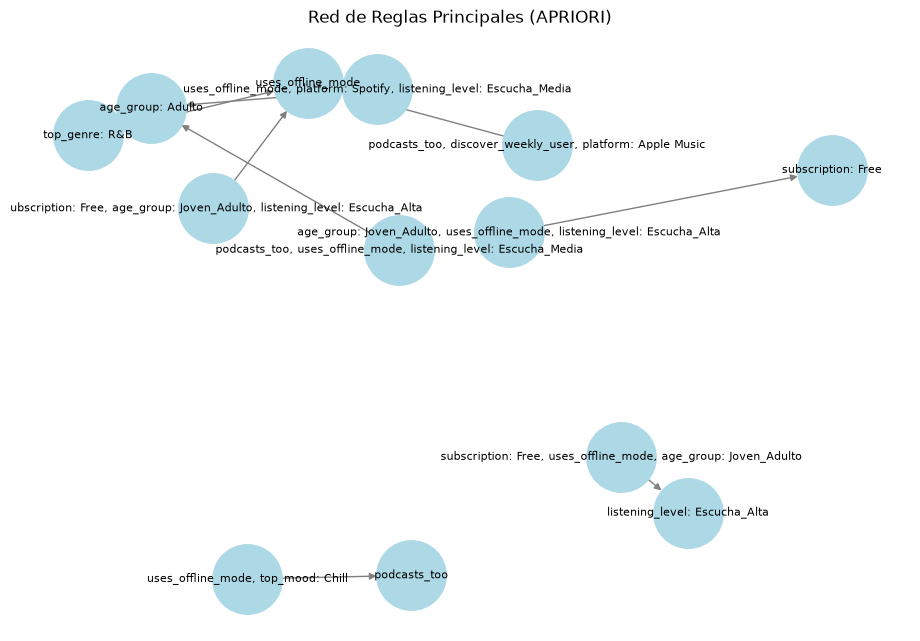

In [22]:
fp_model.graficar_red(top_n=8)

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 04</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Red de Reglas Principales (APRIORI)</div></div>

* **Estructura de las conexiones:** En este gráfico podemos visualizar los nodos y las direcciones (antecedentes hacia consecuentes) de las 8 reglas principales más fuertes obtenidas mediante el modelo. Además, nos permite identificar cómo interactúan de manera combinada distintas variables de los usuarios.
* **Agrupaciones y hallazgos clave:** Con este gráfico podemos apreciar clústeres interesantes, donde características demográficas y de comportamiento como los grupos de edad (`age_group: Joven_Adulto`), el uso de modo offline, niveles de escucha (`Escucha_Alta` o `Escucha_Media`) y tipos de suscripción (`subscription: Free` o plataformas específicas)— se conectan directamente para predecir patrones de consumo musical muy concretos.

### 4.2 FP-Growth

In [23]:
fp_model.fit(metodo="fpgrowth", min_support=0.05, min_confidence=0.6)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"frozenset({uses_offline_mode, platform: Apple ...",frozenset({discover_weekly_user}),0.10275,0.57,0.06175,0.600973,1.054339,1.0,0.003183,1.077622,0.057440,0.101064,0.072031,0.354653
1,frozenset({top_genre: R&B}),frozenset({discover_weekly_user}),0.08525,0.57,0.05350,0.627566,1.100993,1.0,0.004908,1.154567,0.100278,0.088907,0.133874,0.360713
2,"frozenset({uses_offline_mode, platform: Spotif...",frozenset({discover_weekly_user}),0.09125,0.57,0.05550,0.608219,1.067051,1.0,0.003488,1.097552,0.069148,0.091622,0.088882,0.352794
3,"frozenset({top_genre: Pop, podcasts_too})",frozenset({discover_weekly_user}),0.08300,0.57,0.05225,0.629518,1.104418,1.0,0.004940,1.160650,0.103103,0.086975,0.138414,0.360592
4,frozenset({subscription: Student}),frozenset({discover_weekly_user}),0.10025,0.57,0.06050,0.603491,1.058757,1.0,0.003357,1.084465,0.061679,0.099221,0.077887,0.354816


<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación de los resultados usando FP-Growth</div></div>

* **Hallazgos principales:** Las reglas generadas se centran de forma consistente en predecir el uso de la función `discover_weekly_user` a partir de antecedentes clave como el tipo de suscripción si es (*Student*), géneros musicales (*R&B*, *Pop*), el uso de podcasts y plataformas específicas (*Apple Music*, *Spotify*). Lo que demuestra que los usuarios con estos perfiles específicos tienen una alta probabilidad (confianza superior a 0.6) de adoptar las listas de recomendación semanales.

In [24]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por="lift", lift_minimo=1.10)
print(tabla_reglas)

                                 antecedents  \
3  frozenset({top_genre: Pop, podcasts_too})   
1                frozenset({top_genre: R&B})   

                         consequents  support  confidence      lift  
3  frozenset({discover_weekly_user})  0.05225    0.629518  1.104418  
1  frozenset({discover_weekly_user})  0.05350    0.627566  1.100993  


<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Reglas filtradas por Lift (FP-Growth)</div></div>

* **Hallazgo clave:** Se observa que destaca una regla principal con un *lift* de ~1.18 y una confianza superior al 60%, donde antecedentes combinados (como el uso del modo offline y grupos de edad específicos) predicen un nivel de escucha alto (`listening_level: Escucha_Alta`). El resto de las reglas muestran fuertes relaciones hacia el uso de `discover_weekly_user` impulsadas por estados de ánimo (*Happy*), géneros (*R&B*, *Pop*) y tipos de suscripción (*Student*).

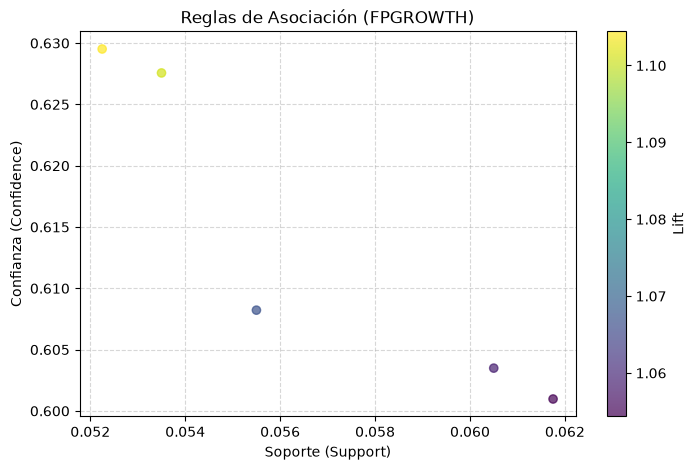

In [25]:
fp_model.graficar_dispersion()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Gráfico de Dispersión (FPGROWTH)</div></div>

* **Hallazgo clave:** Las reglas que se pueden observar ubicadas en la parte superior izquierda (con menor soporte, ~0.052 - 0.053, pero mayor confianza, ~0.63) presentan los valores más altos de *Lift* (tonos amarillos, acercándose a 1.10), lo que nos indica que son las asociaciones más selectivas y con mayor fuerza predictiva encontradas por este algoritmo.

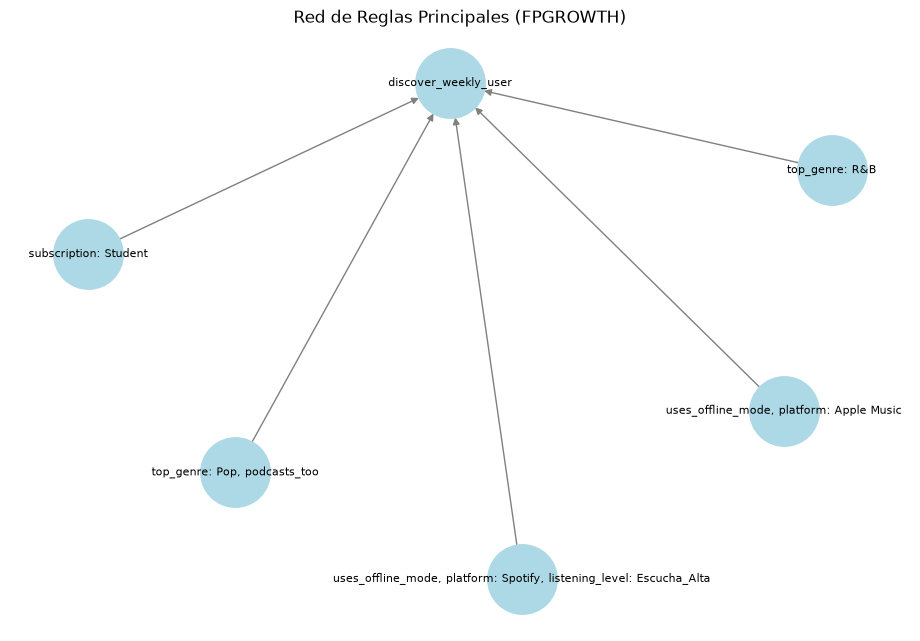

In [26]:
fp_model.graficar_red(top_n=8)

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 04</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Red de Reglas Principales (FPGROWTH)</div></div>

* **Estructura de conexiones:** El objetivo de este gráfico es ilustrarnos las 8 reglas top principales generadas por FPGROWTH, mostrando cómo diversos antecedentes confluyen de manera directa hacia un nodo central y consecuente común: `discover_weekly_user`.
* **Hallazgo clave:** Podemos visualizar de manera clara que características de los usuarios como el uso de *Apple Music* y *Spotify* (en combinación con modo offline y escucha alta), el consumo de podcasts con preferencia por género *Pop*, géneros como *R&B*, y tipos de suscripción (*Student*) actúan como predictores totalmente sólidos para la adopción de las listas de recomendación semanal en la plataforma.

### 4.3 Eclat

In [27]:
fp_model.fit(metodo="eclat", min_support=0.03, min_confidence=0.6)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"frozenset({subscription: Free, age_group: Jove...",frozenset({listening_level: Escucha_Alta}),0.06025,0.5085,0.03625,0.601660,1.183205,1.0,0.005613,1.233870,0.164765,0.068075,0.189542,0.336474
1,"frozenset({podcasts_too, age_group: Joven_Adul...",frozenset({discover_weekly_user}),0.05725,0.5700,0.03450,0.602620,1.057228,1.0,0.001868,1.082088,0.057418,0.058203,0.075861,0.331573
2,"frozenset({uses_offline_mode, platform: Apple ...",frozenset({discover_weekly_user}),0.10275,0.5700,0.06175,0.600973,1.054339,1.0,0.003183,1.077622,0.057440,0.101064,0.072031,0.354653
3,"frozenset({podcasts_too, uses_offline_mode, pl...",frozenset({discover_weekly_user}),0.05100,0.5700,0.03075,0.602941,1.057792,1.0,0.001680,1.082963,0.057570,0.052097,0.076607,0.328444
4,"frozenset({age_group: Adulto, top_mood: Sleep})",frozenset({discover_weekly_user}),0.05350,0.5700,0.03250,0.607477,1.065748,1.0,0.002005,1.095476,0.065179,0.054992,0.087155,0.332247
5,frozenset({top_genre: R&B}),frozenset({discover_weekly_user}),0.08525,0.5700,0.05350,0.627566,1.100993,1.0,0.004908,1.154567,0.100278,0.088907,0.133874,0.360713
6,"frozenset({uses_offline_mode, platform: Spotif...",frozenset({discover_weekly_user}),0.09125,0.5700,0.05550,0.608219,1.067051,1.0,0.003488,1.097552,0.069148,0.091622,0.088882,0.352794
7,"frozenset({subscription: Premium, listening_le...",frozenset({discover_weekly_user}),0.05250,0.5700,0.03150,0.600000,1.052632,1.0,0.001575,1.075000,0.052770,0.053299,0.069767,0.327632
8,"frozenset({podcasts_too, top_mood: Sad})",frozenset({discover_weekly_user}),0.06075,0.5700,0.03650,0.600823,1.054076,1.0,0.001872,1.077216,0.054620,0.061422,0.071682,0.332429
9,"frozenset({top_genre: Pop, podcasts_too})",frozenset({discover_weekly_user}),0.08300,0.5700,0.05225,0.629518,1.104418,1.0,0.004940,1.160650,0.103103,0.086975,0.138414,0.360592


<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación de los resultados (ECLAT)</div></div>

* **Hallazgos principales:** Las reglas extraídas nos muestran relaciones muy consistentes con los métodos anteriores, destacando asociaciones entre patrones de escucha (como modo offline, edad, consumo de podcasts y estados de ánimo) y la adopción de funciones clave como `discover_weekly_user` o niveles de escucha alta, con métricas de confianza estables por encima del 60%.

In [28]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por="lift", lift_minimo=1.15)
print(tabla_reglas)

                                         antecedents  \
0  frozenset({subscription: Free, age_group: Jove...   

                                  consequents  support  confidence      lift  
0  frozenset({listening_level: Escucha_Alta})  0.03625     0.60166  1.183205  


<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Reglas filtradas por Lift (ECLAT)</div></div>

* **Hallazgo clave:** Se destaca una regla muy sólida con un *lift* de ~1.18 y una confianza superior al 60% ($\text{confidence} = 0.601$), donde antecedentes combinados como el uso del modo offline y grupos de edad específicos predicen directamente un nivel de escucha alto (`listening_level: Escucha_Alta`).

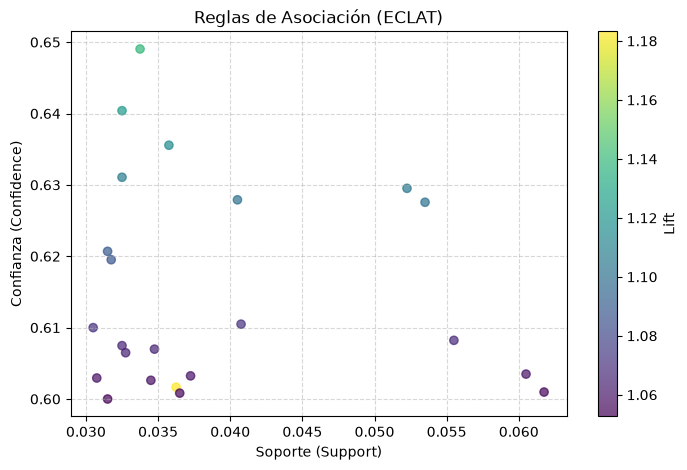

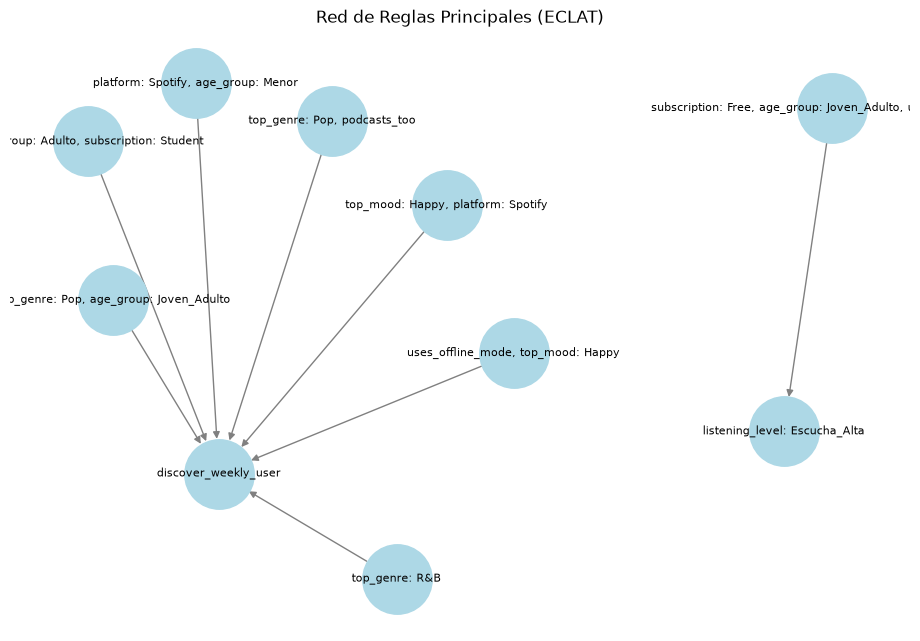

In [29]:
fp_model.graficar_dispersion()
fp_model.graficar_red(top_n=8)

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Gráfico de Dispersión (ECLAT)</div></div>

* **Hallazgo clave:** Las asociaciones con mayor *Lift* (tonos claros que alcanzan hasta ~1.18) se encuentran localizadas en la región superior izquierda, combinando soportes bajos (cercanos a 0.035) con los niveles más altos de confianza (~0.65), lo que nos evidencia los patrones más selectivos y significativos detectados por el algoritmo.

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 04</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Red de Reglas Principales (ECLAT)</div></div>

* **Hallazgo clave:** Gracias a este gráfico podemos notar evidenciado que combinaciones de variables como el consumo de podcasts con géneros (*Pop*, *R&B*), tipos de suscripción (*Student* en adultos), estados de ánimo alegres (*Happy*) en plataformas como *Spotify*, y el uso en modo offline por usuarios menores de edad, actúan como precursores sólidos en la adopción de las listas de recomendación semanal de la plataforma.

### 4.4 Conclusiones de las reglas de asociación

El desarrollo de este proyecto permitió aplicar con éxito técnicas de minería de datos sobre el comportamiento de los usuarios en el servicio de streaming musical. Mediante el uso de los algoritmos Apriori, FP-Growth y ECLAT, fue posible analizar las bases de datos y extraer patrones de comportamiento muy claros.
Los resultados demostraron que los tres algoritmos coinciden en hallazgos clave: características como el uso del modo offline, el consumo de podcasts, géneros musicales específicos (como Pop y R&B) y ciertos tipos de suscripción están fuertemente relacionados con el uso de funciones populares como la lista de recomendaciones semanales y niveles altos de escucha.

* **Consistencia en los Patrones de Comportamiento:** Los tres algoritmos demostraron una gran solidez al coincidir en hallazgos similares bajo los umbrales establecidos. Se identificó que las características de los usuarios como el uso del modo offline, el consumo de podcasts, géneros musicales específicos (*R&B*, *Pop*) y tipos de suscripción (*Student*),están fuertemente asociadas a la adopción de funciones clave de la plataforma, destacando la función `discover_weekly_user` y los niveles de escucha alta.
* **Eficiencia Algorítmica:** Si bien los métodos estructurales difieren en su procesamiento, tanto Apriori como FP-Growth y ECLAT permitieron aislar reglas con altos niveles de confianza (superiores al 60%) y valores de *lift* relevantes (alcanzando hasta ~1.22), descartando asociaciones puramente aleatorias.
* **Valor Práctico:** Los *insights* descubiertos ofrecen una base analítica sólida para comprender la dinámica de la audiencia, facilitando la optimización de sistemas de recomendación personalizados y estrategias de segmentación de contenido más efectivas en plataformas de streaming musical.

En definitiva, estos hallazgos ofrecen información muy valiosa y realista para entender mejor a los usuarios, lo que facilita la toma de decisiones para mejorar las recomendaciones de contenido dentro de la plataforma.

## 5. Modelado (Clusterización)

In [30]:
raw_songs.datos

,listener_id,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,1,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,39.3,False,Sleep,False,True
1,2,21,Germany,Spotify,Free,Classical,Drake,249,68,10,18.3,True,Workout,True,True
2,3,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,22.7,True,Sad,False,True
3,4,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,29.4,True,Sad,True,False
4,5,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,37.7,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3996,26,France,Spotify,Family,Pop,SZA,197,55,6,15.3,False,Workout,True,False
3996,3997,35,Germany,YouTube Music,Free,Rock,Ariana Grande,320,77,13,9.2,True,Sad,False,True
3997,3998,43,India,Apple Music,Free,Hip-Hop,Dua Lipa,99,38,5,14.0,False,Happy,True,True
3998,3999,26,India,Apple Music,Student,Indie,SZA,76,31,7,36.1,False,Happy,False,False


In [31]:
clt_songs = raw_songs.datos.drop(columns=["listener_id"]).copy()

In [32]:
clt_songs = about_data(clt_songs)
clt_songs.estandarizar()

Datos cargados con éxito a partir de la tabla
Columnas estandarizadas: ['age', 'daily_listening_minutes', 'songs_per_day', 'playlists_count', 'skip_rate_pct']


,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,-0.447829,Australia,Apple Music,Free,R&B,Kendrick Lamar,0.606097,0.593475,0.001817,0.942634,False,Sleep,False,True
1,-0.796877,Germany,Spotify,Free,Classical,Drake,1.278286,1.152510,0.332118,-0.834862,True,Workout,True,True
2,0.482966,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,-1.039607,-1.123560,0.662420,-0.462435,True,Sad,False,True
3,1.297411,Japan,Apple Music,Free,Pop,Burna Boy,-0.494902,-0.684318,-0.328485,0.104671,True,Sad,True,False
4,-0.564178,India,Spotify,Family,Country,Olivia Rodrigo,-0.448544,-0.604456,1.323023,0.807205,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,-0.215130,France,Spotify,Family,Pop,SZA,0.675634,0.633406,-0.989088,-1.088790,False,Workout,True,False
3996,0.832014,Germany,YouTube Music,Free,Rock,Ariana Grande,2.101139,1.511890,1.323023,-1.605111,True,Sad,False,True
3997,1.762809,India,Apple Music,Free,Hip-Hop,Dua Lipa,-0.460134,-0.045422,-1.319390,-1.198826,False,Happy,True,True
3998,-0.215130,India,Apple Music,Student,Indie,SZA,-0.726692,-0.324939,-0.658787,0.671777,False,Happy,False,False


In [33]:
cols_modelo = ["age", "daily_listening_minutes", "playlists_count", "skip_rate_pct"]
X_escalado = clt_songs.datos[cols_modelo]

In [34]:
red_model = Reduccion_Dimensionalidad(df_escalado=X_escalado, df_original=clt_songs.datos)

### 5.1 ACP

In [35]:
cols_comportamiento = [
    "skip_rate_pct",
    "playlists_count",
    "daily_listening_minutes",
]

modelo = ClusteringReduccion(X_escalado[cols_comportamiento])

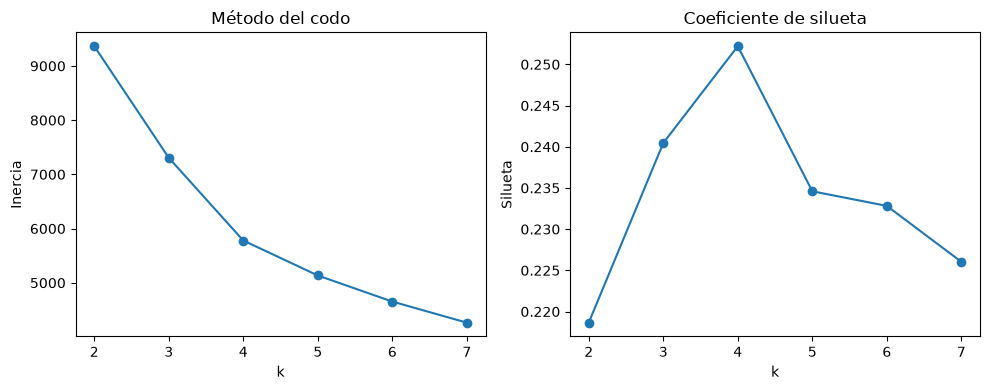

In [36]:
modelo.k_optimo(k_min=2, k_max=7)

In [37]:
df_acp = modelo.acp_kmeans(n_clusters=4)
df_acp.head()

,dim1,dim2,cluster
0,0.286977,0.403037,3
1,-1.395033,0.695385,1
2,0.467270,0.088375,2
3,0.345372,-0.483037,2
4,1.119183,1.127289,3


<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del head</div></div>

Las tres variables tienen correlaciones muy bajas entre sí, por lo que dim1 y dim2 lo que hacen es capturar los ejes relativamente independientes (alrededor de 34.4% y 33.6% de varianza cada uno en un ACP estándar) y se complementan entre sí para separar los hábitos de escucha.
Al segmentarlo en 4 grupos, los patrones de comportamiento se reparten entre:

Un perfil de alta dedicación diaria (más minutos y canciones por día, con poca omisión),

Un perfil de consumo moderado y constante (tiempo medio, pocas playlists y poca omisión),

Un perfil de mayor selectividad / rotación (muchas playlists, tiempo medio y omisión alta), y

Un perfil de consumo casual con alta omisión (el menor tiempo diario y el mayor skip rate).


In [38]:
# Perfil de cada cluster en escala original (promedios) y cantidad de usuarios
perfil_acp = (
    raw_songs.datos.drop(columns=["listener_id"])
    .select_dtypes("number")
    .groupby(df_acp["cluster"])
    .mean()
    .round(1)
)
perfil_acp["cantidad"] = df_acp["cluster"].value_counts().sort_index()
perfil_acp

,age,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,cantidad
cluster,,,,,,
0,28.1,135.6,38.1,6.7,20.4,1187
1,27.7,254.5,72.1,10.4,20.9,697
2,27.7,80.2,22.6,7.8,35.7,1135
3,27.8,127.9,36.2,12.2,34.0,981


In [39]:
graf = GraficosClustering(datos_original=clt_songs.datos, df_acp=df_acp)

graf.scatter_2D()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico de Clustering</div></div>

Nube continua con fronteras lineales: los cuatro grupos forman una sola nube de forma de abanico sin brechas vacías entre ellos.
Esto confirma que K-Means está segmentando un espectro continuo de hábitos de uso en cuatro zonas bien delimitadas en lugar de grupos aislados.


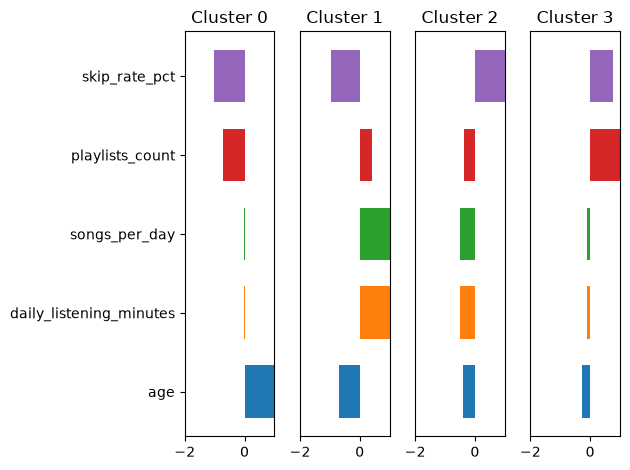

In [40]:
graf.bar_plot(scale=True)

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del bar plot</div></div>

Validación cruzada con songs_per_day: aunque songs_per_day no entró en el ACP, replica exactamente el patrón de daily_listening_minutes (alto en Cluster 1, bajo en Cluster 2 y intermedio en Clusters 0 y 3), confirmando coherencia interna en la intensidad de uso.
El diferenciador clave entre Cluster 0 y Cluster 3: es que ambos escuchan prácticamente lo mismo al día (≈136 y ≈128 minutos), pero se separan porque el Cluster 3 construye muchas más playlists (12.2 contra 6.7) y salta bastante más música (34.0% contra 20.4%).
La edad es prácticamente homogénea en los cuatro grupos (27.7–28.1 años), no es factor real de segmentación aunque visualmente destaque por el escalado.


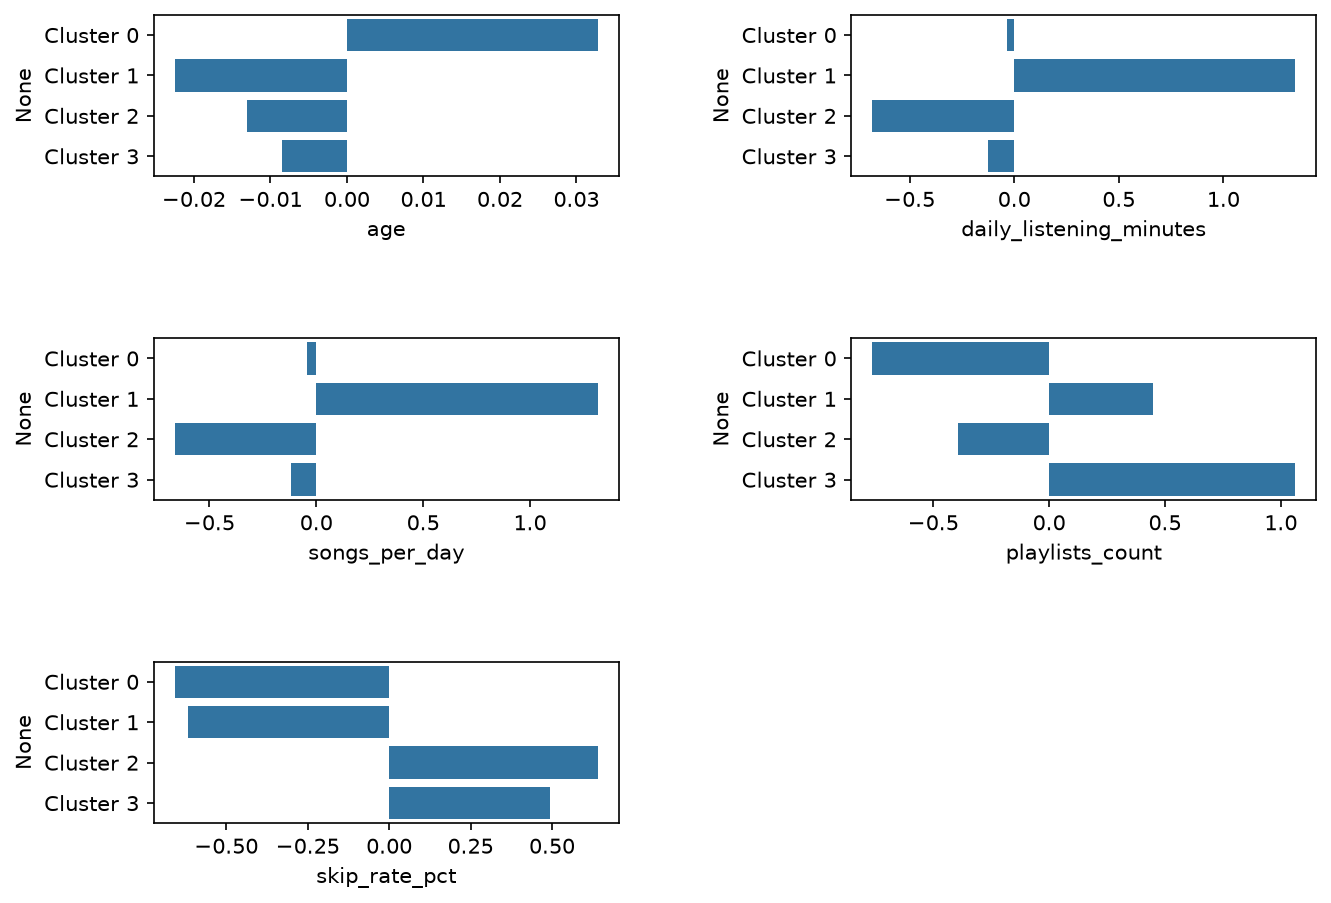

In [41]:
graf.bar_plot_detail()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 04</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico bar plot detallado</div></div>

Cluster 1 (oyentes intensivos y fieles, 697 usuarios): destaca por tener mucho mayor volumen de escucha diaria (≈254 minutos y ≈72 canciones por día) y una de las menores tasas de omisión (20.9%).
Cluster 3 (curadores selectivos / alta rotación, 981 usuarios): lidera en cantidad de playlists (12.2) y tiene una tasa de skips alta (34.0%), con un tiempo diario de escucha medio (≈128 minutos).
Cluster 2 (oyentes casuales con alta omisión, 1,135 usuarios): tiene el menor tiempo y la menor cantidad de canciones por día (≈80 minutos y ≈23 canciones) y la tasa de skips más alta (35.7%).
Cluster 0 (oyentes moderados y constantes, 1,187 usuarios): escucha un tiempo medio (≈136 minutos), tiene la menor cantidad de playlists (6.7) y la menor tasa de skips (20.4%).


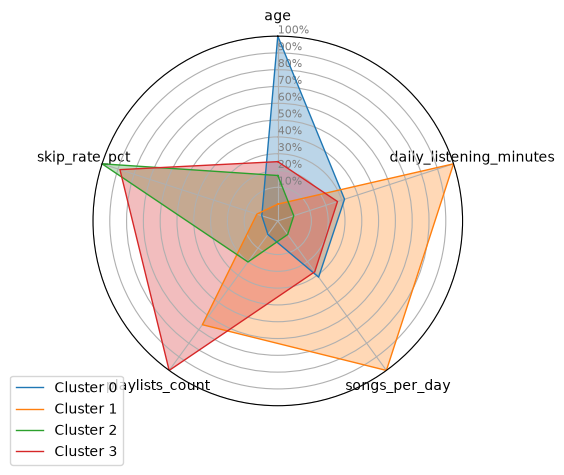

In [42]:
graf.radar_plot()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 05</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico radar</div></div>

Cluster 1 (mayor consumo): alcanza el 100% en daily_listening_minutes y songs_per_day, un nivel alto en playlists_count (66%), y casi 0% en skip_rate_pct (3%). Representa a los oyentes más activos y fieles, que escuchan mucha música sin saltar canciones.
Cluster 3 (curadores selectivos): domina al 100% en playlists_count y llega a 89% en skip_rate_pct, pero se ubica cerca del 27% en tiempo y canciones diarias. Son usuarios que organizan muchas listas, consumen un tiempo medio al día y saltan pistas con frecuencia.
Cluster 2 (oyentes casuales con alta omisión): marca el mínimo (0%) en daily_listening_minutes y songs_per_day, un valor bajo (20%) en playlists_count y el máximo (100%) en skip_rate_pct. Es el segmento que menos escucha y más omite.
Cluster 0 (oyentes moderados): marca el mínimo (0%) en playlists_count y skip_rate_pct, con un nivel medio-bajo (~32%) en tiempo y canciones diarias. Escucha de forma regular, con pocas playlists y sin saltar mucho.
Nota sobre age: aunque el gráfico muestra al Cluster 0 en 100% y al Cluster 1 en 0%, en la realidad todos promedian entre 27.7 y 28.1 años (diferencia de apenas 0.4 años); el escalado relativo 0%–100% exagera visualmente esa mínima variación.


### 5.2 t-SNE

#### 5.2.1 Construcción de la proyección t-SNE

Se utilizan `age`, `daily_listening_minutes`, `playlists_count` y `skip_rate_pct`, estandarizadas dentro de la clase.

In [43]:
red_model = AnalisisTSNE(clt_songs.datos)
red_model.ajustar(perplexity=30)
red_model.tsne_df.head()

,TSNE_1,TSNE_2
0,34.004791,-18.875189
1,-32.302589,32.213722
2,18.207544,-14.142501
3,-7.856420,-44.356480
4,32.092224,1.369302


In [44]:
df_tsne = modelo.tsne_kmeans(n_clusters=4, perplexity=30)
graf_tsne = GraficosClustering(datos_original=clt_songs.datos, df_acp=df_tsne)
graf_tsne.scatter_2D(title="Clústeres en t-SNE")

#### 5.2.2 Usuarios según plataforma


In [45]:
red_model.graficar("platform", "Proyección t-SNE (Estructura Local) — Agrupado por platform").show()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico por plataforma musical</div></div>


En este gráfico, cada punto representa a una persona y los colores indican la plataforma que utiliza, como Spotify, Apple Music, Amazon Music, Tidal, SoundCloud o YouTube Music. Al observar la distribución, los usuarios de distintas plataformas aparecen mezclados en varias zonas, en lugar de formar grupos completamente separados. Esto nos dice que utilizar una aplicación u otra no necesariamente significa tener hábitos de escucha diferentes.

Es importante recordar que el t-SNE organizó los puntos tomando en cuenta la edad, los minutos diarios de escucha, la cantidad de listas de reproducción y el porcentaje de canciones que se saltan. La plataforma se añadió después para colorear el resultado, no para construirlo. Por eso, cuando vemos puntos cercanos de distintos colores, podemos entender que esas personas se parecen en sus hábitos, aunque escuchen música en aplicaciones diferentes. No sería correcto afirmar que una plataforma tiene usuarios más activos o que causa determinados comportamientos solo con este gráfico.

#### 5.2.3 Usuarios según género musical

In [46]:
red_model.graficar("top_genre", "Proyección t-SNE (Estructura Local) — Agrupado por top_genre").show()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico por género musical favorito</div></div>


Aquí se muestra la misma distribución de personas, pero ahora cada color corresponde a su género musical favorito. Aparecen estilos muy variados, como Pop, Rock, Hip-Hop, R&B, música clásica, K-Pop y otros. Lo interesante es que los colores se encuentran repartidos por el gráfico y no se aprecia una separación clara donde cada género tenga su propio espacio.

Esto permite interpretar que dos personas pueden tener gustos musicales completamente distintos y, aun así, escuchar una cantidad parecida de minutos al día, manejar una cantidad similar de playlists o saltarse canciones con una frecuencia semejante. Dicho de forma sencilla, el género favorito no parece ser suficiente para distinguir los hábitos de escucha representados aquí. Además, como el género no se utilizó para calcular el t-SNE, este resultado no demuestra que los gustos musicales sean iguales, sino que personas con gustos diferentes pueden comportarse de manera similar al escuchar música.

#### 5.2.4 Usuarios según estado de ánimo



In [47]:
red_model.graficar("top_mood", "Proyección t-SNE (Estructura Local) — Agrupado por top_mood").show()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico por estado de ánimo</div></div>


En esta visualización, los colores representan el estado de ánimo o contexto que cada persona relaciona con su música, por ejemplo, relajarse, concentrarse, hacer ejercicio, dormir o sentirse con energía. Se observa que las categorías se distribuyen por distintas partes del gráfico y que varias coinciden en las mismas zonas. No hay una división evidente que permita identificar a cada estado de ánimo como un grupo independiente.

Esto tiene sentido porque escuchar música para estudiar o descansar no determina por sí solo cuántos minutos se escucha al día ni cuántas listas se tienen. Por ejemplo, una persona que escucha música para concentrarse podría tener hábitos muy parecidos a los de otra que la usa para entrenar. En conclusión, el estado de ánimo aporta información sobre el motivo o el ambiente de escucha, pero en esta representación no marca una diferencia clara entre los perfiles. Tampoco debemos interpretar la cercanía de los puntos como una relación emocional directa: el modelo compara hábitos numéricos, no sentimientos.

#### 5.2.5 Usuarios y consumo de podcasts

In [48]:
red_model.graficar("podcasts_too", "Proyección t-SNE (Estructura Local) — Agrupado por podcasts_too").show()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 04</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico por consumo de podcasts</div></div>


Este gráfico divide a los usuarios en dos categorías: quienes también escuchan podcasts (`True`) y quienes no (`False`). Al comparar los colores, ambos tipos de usuarios aparecen en diferentes regiones de la proyección y comparten muchos espacios. Por lo tanto, no se ve una frontera clara que separe a las personas según consuman podcasts o no.

Esto sugiere que escuchar podcasts no es, por sí solo, una característica que permita reconocer un patrón de consumo musical totalmente diferente dentro de las variables analizadas. Una persona que escucha podcasts puede dedicarle a la música un tiempo parecido al de alguien que no los escucha, tener una cantidad similar de playlists y saltarse canciones con una frecuencia comparable. Eso sí, este análisis no incluye cuánto tiempo se dedica específicamente a los podcasts, así que no podemos sacar conclusiones sobre ese consumo ni afirmar que los podcasts aumentan o disminuyen el tiempo de escucha musical.

#### 5.2.6 Intensidad diaria de escucha

La clase divide descriptivamente los minutos diarios en tres niveles con cantidades similares de usuarios. **No son clústeres**.

In [49]:
    red_model.graficar_intensidad_escucha().show()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 05</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico por intensidad de escucha</div></div>


En este último gráfico, las personas se clasifican en intensidad **baja, media y alta** según sus minutos diarios de escucha. A diferencia de los gráficos anteriores, aquí sí se está coloreando el resultado con una categoría que sale directamente de una de las variables utilizadas para construir el t-SNE. Por eso, tiene sentido que algunas zonas muestren una mayor presencia de un nivel de intensidad, aunque también puede haber puntos de diferentes niveles cercanos entre sí.

Lo que podemos entender es que el tiempo diario dedicado a la música ayuda a explicar parte de las semejanzas y diferencias entre los usuarios, pero no es el único factor. La edad, la cantidad de playlists y el porcentaje de canciones que se saltan también influyen en la posición de cada punto. Además, **baja, media y alta no son clústeres descubiertos por el modelo**: son categorías descriptivas creadas a partir de los minutos diarios, con cantidades similares de usuarios. Por eso, no debemos confundirlas con grupos que el t-SNE haya encontrado automáticamente ni interpretar los ejes como minutos reales.

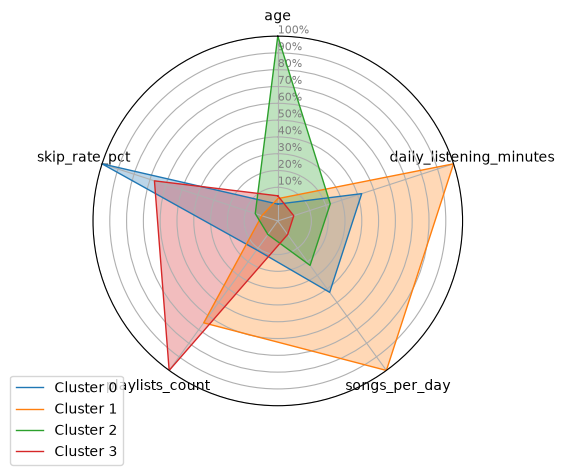

In [50]:
graf_tsne = GraficosClustering(datos_original=clt_songs.datos, df_acp=df_tsne)
graf_tsne.radar_plot()

#### 5.2.7 Conclusiones del t-SNE

Después de revisar las cinco visualizaciones, podemos ver que los hábitos de escucha no se explican únicamente por la plataforma, el género favorito, el estado de ánimo o el hecho de escuchar podcasts. En los gráficos de esas categorías hay bastante mezcla de colores, lo cual nos muestra que personas con preferencias distintas pueden compartir comportamientos parecidos al escuchar música.

La intensidad de escucha nos ayuda a mirar el resultado desde otra perspectiva, porque está relacionada directamente con los minutos diarios, una de las cuatro variables que sí se usaron en el análisis. Aun así, el comportamiento de cada usuario depende de la combinación de varias características y no de una sola.

En general, el t-SNE fue útil para **visualizar semejanzas locales** entre usuarios a partir de sus hábitos de escucha. Sin embargo, hay que tener presente que es una técnica de reducción de dimensionalidad y **no un método de clustering**. Los ejes `TSNE_1` y `TSNE_2` no tienen una interpretación directa, y las distancias grandes o los espacios vacíos del gráfico no prueban por sí solos que existan grupos naturales. Para comprobar diferencias entre categorías o identificar grupos reales, sería necesario complementar este análisis con otras técnicas y medidas.

### 5.3 UMAP

UMAP es otra técnica de reducción de dimensionalidad, parecida al t-SNE: toma varias características de cada usuario y las aplana en un mapa de 2 dimensiones donde las personas con hábitos parecidos quedan cerca. Es como dibujar el mapa de un país: los ejes (`dim1` y `dim2`) no tienen unidades, lo que importa es quién queda cerca de quién. Sobre ese mapa se aplica K-Means para armar los grupos.

Las variables se estandarizan antes de entrar al modelo, para que ninguna pese más solo por tener números más grandes. Se probaron **tres versiones** para ver qué pasaba al cambiar las variables:

* **Versión 1:** edad, minutos diarios, playlists y podcasts (4 grupos).
* **Versión 2:** lo mismo, pero sin podcasts (4 grupos).
* **Versión 3:** edad, minutos diarios, playlists y plataforma (3 grupos).

#### 5.3.1 UMAP con edad, minutos, playlists y podcasts

In [51]:
RUTA_LIMPIO = str(RAIZ / "DATA" / "PROCESSED" / "music_streaming_habits_limpio.csv")

seg = MODELO_UMAP(RUTA_LIMPIO)
seg.preparar_datos(["edad", "minutosXdia", "playlist", "podcast"])

       edad  minutosXdia  playlist   podcast
0 -0.447829     0.606097  0.001817  1.066186
1 -0.796877     1.278286  0.332118  1.066186
2  0.482966    -1.039607  0.662420  1.066186
3  1.297411    -0.494902 -0.328485 -0.937923
4 -0.564178    -0.448544  1.323023  1.066186
(4000, 4)


In [ ]:
seg.aplicar_umap()
seg.agrupar(n_clusters=4)

In [ ]:
seg.graficar_clusters(hover=["plataforma", "genero_favorito", "estado_animo"])

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del mapa UMAP con podcasts</div></div>


* **Hallazgo clave:** En el mapa se ven **dos islas separadas por un espacio vacío**. La de la izquierda es el cluster 1 (1,872 usuarios) y la de la derecha junta los clusters 0, 2 y 3, que sí se tocan entre sí.
* **Lo que significa:** esa isla de la izquierda no es un hábito de escucha distinto, es el efecto de la variable `podcast`. Como solo tiene dos valores (sí/no), UMAP la usa como un corte limpio y parte a la gente en dos mitades. Es como separar un salón entre quienes usan lentes y quienes no: la división es clara, pero no dice cómo se comportan.

In [ ]:
seg.perfil_clusters()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación de los perfiles de cada cluster</div></div>


* **Cluster 0 (705 usuarios):** escucha mucho (≈238 minutos al día), con 8.9 playlists y sin podcasts.
* **Cluster 1 (1,872 usuarios, el 46.8%):** ≈136 minutos al día, 8.9 playlists y **todos** escuchan podcasts.
* **Cluster 2 (634 usuarios):** el que menos escucha (≈90 minutos) y con pocas playlists (6.4).
* **Cluster 3 (789 usuarios):** escucha poco (≈96 minutos) pero tiene muchas playlists (11.4).
* **Edad:** casi igual en los cuatro grupos (entre 27.6 y 28.7 años), así que no separa a nadie.

In [ ]:
seg.graficar_barras_clusters()
seg.graficar_radar_clusters()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico de barras y del radar</div></div>


* **Hallazgo clave:** `podcast` es la barra más marcada: +1.07 en el cluster 1 y -0.94 en los otros tres. Casi todo lo que distingue al cluster 1 es esa sola variable.
* **Lo demás:** el cluster 0 es el único con minutos realmente altos (+1.15), y las playlists separan al cluster 3 (+0.79) del cluster 2 (-0.85). La edad queda en cero en todos.
* **Lección:** el radar cuenta lo mismo con otra forma. Una variable de sí/no domina el mapa y tapa los patrones de comportamiento, por eso en el siguiente paso se vuelve a correr el modelo sin ella.

#### 5.3.2 UMAP sin la variable podcast

In [ ]:
seg_sin_podcast = MODELO_UMAP(RUTA_LIMPIO)
seg_sin_podcast.preparar_datos(["edad", "minutosXdia", "playlist"])
seg_sin_podcast.aplicar_umap()
seg_sin_podcast.agrupar(n_clusters=4)
seg_sin_podcast.graficar_clusters(hover=["plataforma", "genero_favorito", "estado_animo"])
seg_sin_podcast.perfil_clusters()
seg_sin_podcast.graficar_barras_clusters()
seg_sin_podcast.graficar_radar_clusters()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del mapa UMAP sin podcast</div></div>


* **Hallazgo clave:** sin `podcast` desaparecen las islas. Los puntos forman una sola nube continua y los cuatro grupos se tocan en sus fronteras, con apenas un pequeño espacio vacío en el centro.
* **Lo que significa:** los grupos son zonas de un mismo espectro, como los pisos de un edificio: se distinguen entre sí, pero no hay paredes. K-Means está cortando una nube continua, no encontrando grupos aislados.

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación de los perfiles de cada cluster</div></div>


* **Cluster 0 (1,168 usuarios):** 28.6 años, ≈116 minutos y **12.5 playlists**, la mayor cantidad. Son los curadores de playlists.
* **Cluster 1 (747 usuarios):** los más jóvenes (25.9 años), ≈111 minutos y 9.3 playlists. Uso intermedio.
* **Cluster 2 (1,407 usuarios, el más grande):** 26.3 años, ≈112 minutos y solo 6.3 playlists. Escuchan lo normal pero casi no arman listas.
* **Cluster 3 (678 usuarios, el más pequeño):** los mayores (32.0 años) y los que más escuchan, ≈263 minutos al día. Son los oyentes intensivos.
* **Dato curioso:** tres de los cuatro grupos escuchan casi lo mismo (111 a 116 minutos). Solo el cluster 3 se separa por tiempo; los demás se separan por playlists y edad.

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 03</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico de barras y del radar</div></div>


* **Hallazgo clave:** las barras confirman lo anterior: el cluster 3 sobresale en minutos (+1.44) y edad (+0.49), el cluster 0 en playlists (+1.16) y el cluster 2 queda bajo en playlists (-0.91).
* **Lo que significa:** esta es la versión más útil de UMAP, porque sin la variable de sí/no aparecen perfiles de comportamiento. Coincide con el ACP en dos perfiles: el oyente intensivo y el curador de playlists.

#### 5.3.3 UMAP incluyendo la plataforma

Ahora se agrega la plataforma (convertida en columnas de sí/no) para ver si los usuarios se separan según el tipo de plataforma que usan.

In [ ]:
seg_plat = MODELO_UMAP(RUTA_LIMPIO)
seg_plat.preparar_datos(["edad", "minutosXdia", "playlist"], categoricas=["plataforma"])
seg_plat.aplicar_umap()
seg_plat.agrupar(n_clusters=3)
seg_plat.graficar_clusters(hover=["plataforma", "genero_favorito", "estado_animo"])
seg_plat.graficar_barras_clusters()

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 01</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del mapa UMAP con plataforma</div></div>


* **Hallazgo clave:** el mapa cambia por completo: aparecen **seis islas compactas y bien separadas**, una por plataforma, y K-Means las junta en 3 grupos.
* **Lo que significa:** esto no es un descubrimiento sobre los usuarios. Al convertir la plataforma en seis columnas de sí/no, esas columnas pesan más en el cálculo que las tres variables numéricas, y el modelo termina agrupando casi solo por plataforma.

<div style="background:#edf5f9;border-left:5px solid #1686a1;padding:14px 18px;border-radius:6px;margin:18px 0 14px;font-family:Arial,sans-serif"><div style="font-size:11px;color:#44738b;letter-spacing:1.5px;font-weight:bold">LECTURA DEL RESULTADO 02</div><div style="font-size:19px;color:#12304a;font-weight:bold;margin-top:4px">Interpretación del gráfico de barras</div></div>


* **Cluster 0 (1,405 usuarios):** Apple Music (+1.00), SoundCloud (+0.50) y Tidal (+0.45).
* **Cluster 1 (1,591 usuarios):** Spotify (+1.23). Es exactamente la cantidad de usuarios de Spotify en el dataset.
* **Cluster 2 (1,004 usuarios):** YouTube Music (+1.36) y Amazon Music (+0.87).
* **Hábitos de escucha:** edad, minutos y playlists quedan prácticamente en cero en los tres grupos (entre -0.03 y 0.04). Es decir, los usuarios de las tres plataformas escuchan igual.
* **Lección:** confirma lo visto en el t-SNE: la plataforma no determina cómo escucha la gente.

#### 5.3.4 Conclusiones del UMAP


Cada versión del modelo dejó una enseñanza distinta:

* **Con podcast:** la variable `podcast` manda en el mapa y parte a los usuarios en dos islas. El cluster 1 (1,872 usuarios) es simplemente "los que escuchan podcasts" y no un hábito diferente.
* **Sin podcast:** es la versión más útil para segmentar. Aparecen perfiles de comportamiento: oyentes intensivos (≈263 minutos, 32 años), curadores de playlists (12.5 playlists) y dos grupos con pocas playlists que se separan sobre todo por edad. Los grupos forman una nube continua: hay un gradiente, no fronteras.
* **Con plataforma:** los grupos coinciden con las plataformas y las variables de comportamiento casi no cambian entre ellos. La plataforma no distingue hábitos de escucha.

**Lo que nos queda del UMAP:**

* Las variables de sí/no o por categorías (`podcast`, `plataforma`) pesan demasiado en UMAP con K-Means y pueden dominar el resultado. Conviene usarlas para colorear e interpretar después, como se hizo en el t-SNE, y no para construir el mapa.
* La edad casi no separó nada, salvo en la versión sin podcast, donde el grupo que más escucha también es el de mayor edad.
* El número de clusters se fijó a mano (4, 4 y 3) y en el notebook no se muestra una métrica, como la silueta, que lo respalde. Los grupos hay que tomarlos como una forma útil de describir a los usuarios, no como grupos definitivos.
* Igual que en el t-SNE, los ejes `dim1` y `dim2` no se interpretan directamente, y una distancia grande en el mapa no prueba por sí sola que existan grupos naturales.
* Los tres métodos (ACP, t-SNE y UMAP) coinciden en algo: los hábitos de escucha forman un espectro continuo y no grupos aislados.

## 6. Conclusiones generales del proyecto

Este apartado cierra el proyecto uniendo tres cosas: cómo se siguió la metodología CRISP-DM, qué dejó cada modelo y cómo quedó armado el pipeline.

### 6.1 Conclusiones según CRISP-DM

| Fase | Qué se hizo en el proyecto | Conclusión |
|---|---|---|
| **1. Comprensión del negocio** | Introducción y propósito: entender los hábitos de streaming para mejorar recomendaciones y segmentar usuarios. | El objetivo se cumplió: se encontraron patrones de uso (reglas de asociación) y perfiles de usuarios (clusters) que sirven para recomendar y segmentar, aunque con asociaciones moderadas. |
| **2. Comprensión de los datos** | Ingesta, reporte de calidad, estadísticos, resumen de categóricas y EDA con gráficos (secciones 2 y 3). | El dataset tiene 4,000 usuarios y 15 columnas, sin valores nulos ni duplicados, así que no hubo que imputar nada. Los minutos de escucha tienen un rango muy amplio (de 5 a 697), por lo que hay que estandarizar. |
| **3. Preparación de los datos** | Selección de 9 columnas, edad en 4 etapas de vida, minutos en 3 niveles, columnas de verdadero/falso (`get_dummies`) y estandarización para los clusters. | Cada técnica pide datos distintos: categorías de verdadero/falso para las reglas y variables numéricas estandarizadas para la clusterización. |
| **4. Modelado** | Apriori, FP-Growth y Eclat; ACP con K-Means, t-SNE y UMAP (secciones 4 y 5). | Se aplicaron tres algoritmos de asociación y tres técnicas de reducción de dimensionalidad, cada una con su lectura de resultados. |
| **5. Evaluación** | Lectura de soporte, confianza y *lift*; lectura de perfiles de clusters y de cada gráfico. | Los tres algoritmos de asociación coinciden. Con un *lift* entre ≈1.05 y 1.22, las asociaciones son reales pero moderadas, y los clusters son zonas de un espectro continuo y no grupos aislados. |
| **6. Despliegue** | No hubo un despliegue en producción; lo que se entrega es el notebook y las clases reutilizables. | Los hallazgos se pueden aplicar a recomendaciones y segmentación. Para desplegarlos haría falta, por ejemplo, integrar el flujo de limpieza y los modelos en un proceso automático. |

### 6.2 Conclusiones del modelado

* **Reglas de asociación (Apriori, FP-Growth y Eclat):** los tres algoritmos llegaron a los mismos patrones. Las diferencias están en cómo trabajan por dentro, no en el resultado. Los usuarios con suscripción *Student*, género *R&B* o *Pop*, que escuchan podcasts o usan el modo offline, tienden a usar Discover Weekly, y el modo offline combinado con ciertas edades se asocia con escucha alta. Eso sí, como el 57% de los usuarios ya usa Discover Weekly, una confianza de ≈60% mejora solo un poco lo que se acertaría al azar. Por eso estas reglas sirven como pistas y no como reglas para decidir solas.
* **ACP + K-Means (4 clusters):** se obtuvieron cuatro perfiles claros según intensidad, playlists y skips: oyentes intensivos (697 usuarios, ≈254 minutos y 20.9% de skips), curadores selectivos (981 usuarios, 12.2 playlists y 34.0% de skips), oyentes casuales con alta omisión (1,135 usuarios, ≈80 minutos y 35.7% de skips) y oyentes moderados (1,187 usuarios, ≈136 minutos y 6.7 playlists). La edad no separó a nadie.
* **t-SNE:** sirvió para visualizar semejanzas entre usuarios. Al colorear por plataforma, género, estado de ánimo y podcasts no se ve una separación clara, así que esas categorías no explican por sí solas los hábitos de escucha. Es una técnica de visualización, no de clustering.
* **UMAP (3 versiones):** la versión sin podcast fue la más útil, con perfiles de oyente intensivo, curador de playlists y dos grupos de pocas playlists. Las versiones con `podcast` y con `plataforma` mostraron que las variables de sí/no dominan el mapa.

| Técnica | Variables usadas | Resultado principal |
|---|---|---|
| ACP + K-Means | minutos, playlists y skips | 4 perfiles: intensivos, curadores, casuales y moderados |
| t-SNE | edad, minutos, playlists y skips | Plataforma, género, ánimo y podcasts no separan a los usuarios |
| UMAP sin podcast | edad, minutos y playlists | 4 perfiles: intensivos, curadores y dos grupos de pocas playlists |

**Mensaje común de todos los modelos:** lo que distingue a los usuarios es su **comportamiento** (minutos, playlists y skips), no sus gustos ni la plataforma que usan. Y ese comportamiento forma un espectro continuo, como una pendiente suave y no como escalones.

### 6.3 Conclusiones del pipeline

El flujo del proyecto quedó así:

```
DATA/RAW (csv original)
   -> about_data            calidad de datos y resúmenes
   -> EDA                   gráficos de exploración
   -> preparación           edad y minutos en categorías, get_dummies
   -> Reglas_Asociacion     Apriori / FP-Growth / Eclat

datos estandarizados
   -> ClusteringReduccion + GraficosClustering    ACP + K-Means
   -> AnalisisTSNE                                t-SNE
   -> MODELO_UMAP (lee DATA/PROCESSED)            UMAP
```

* **Programación orientada a objetos:** cada paso es una clase con métodos (cargar, reportar, ajustar, graficar). Es como tener la cocina con todo preparado: cada análisis queda en una o tres líneas y el notebook se lee de arriba abajo como un reporte.
* **Reutilización:** `Reglas_Asociacion` cambia de algoritmo con solo un parámetro (`metodo`), `GraficosClustering` se usa igual para ACP y t-SNE, y `MODELO_UMAP` se corrió tres veces cambiando únicamente las columnas y el número de clusters.
* **Organización:** los datos originales, los procesados, las clases y los modelos viven en carpetas separadas, y la variable `RAIZ` detecta la carpeta del proyecto, así que el notebook corre aunque se abra desde otra ubicación.
* **Puntos a mejorar:**
  * UMAP lee el archivo limpio de `DATA/PROCESSED` (con columnas en español), mientras que el resto parte del csv original (en inglés). El notebook no muestra la celda que genera ese archivo, así que conviene dejar ese paso documentado o ejecutable dentro del flujo.
  * En el ACP el número de clusters se eligió con `k_optimo`, pero en t-SNE y UMAP se fijó a mano. Usar el mismo criterio en los tres haría los resultados más comparables.

### 6.4 Limitaciones y trabajo futuro

* **Reglas de asociación:** con un *lift* máximo de ≈1.22, las reglas son pistas y no certezas. Se podría probar un modelo de clasificación para predecir el uso de Discover Weekly y comparar.
* **Clusters:** conviene validar el número de grupos con métricas como la silueta y probar la estabilidad cambiando parámetros del UMAP.
* **Comparación entre modelos:** UMAP no usó `skip_rate_pct`, que sí entró en el ACP y el t-SNE. Incluirla permitiría compararlos en igualdad de condiciones.
* **Lectura de los mapas:** en t-SNE y UMAP los ejes no tienen una interpretación directa, y los grupos que muestran dependen de las variables elegidas.